In [1]:

print("AI Resume Analyzer and Job Recommendation System")
print("Major Project")
print("Notebook started successfully!")


AI Resume Analyzer and Job Recommendation System
Major Project
Notebook started successfully!


In [2]:

!pip -q install pypdf python-docx pandas numpy scikit-learn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 16.4 MB/s eta 0:00:00


In [3]:

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

print("All libraries imported successfully!")
print("AI Resume Analyzer project is ready to build.")


All libraries imported successfully!
AI Resume Analyzer project is ready to build.


In [4]:

# Step 5: Create the job-role dataset

job_roles = {
    "Data Analyst": [
        "Python", "SQL", "Excel", "Pandas", "Power BI",
        "Statistics", "Data Visualization"
    ],
    "Machine Learning Engineer": [
        "Python", "Machine Learning", "Scikit-learn",
        "Pandas", "NumPy", "TensorFlow", "Docker"
    ],
    "AI Engineer": [
        "Python", "Artificial Intelligence", "Deep Learning",
        "LLM", "RAG", "APIs", "TensorFlow"
    ],
    "NLP Engineer": [
        "Python", "NLP", "Transformers",
        "Hugging Face", "Machine Learning", "Deep Learning"
    ],
    "Computer Vision Engineer": [
        "Python", "OpenCV", "CNN",
        "Deep Learning", "Machine Learning", "YOLO"
    ]
}

# Convert the dataset into a DataFrame
job_df = pd.DataFrame([
    {
        "Job Role": role,
        "Required Skills": ", ".join(skills)
    }
    for role, skills in job_roles.items()
])

print("Job-role dataset created successfully!")
print("Number of job roles:", len(job_df))
display(job_df)


Job-role dataset created successfully!
Number of job roles: 5


,Job Role,Required Skills
0,Data Analyst,"Python, SQL, Excel, Pandas, Power BI, Statisti..."
1,Machine Learning Engineer,"Python, Machine Learning, Scikit-learn, Pandas..."
2,AI Engineer,"Python, Artificial Intelligence, Deep Learning..."
3,NLP Engineer,"Python, NLP, Transformers, Hugging Face, Machi..."
4,Computer Vision Engineer,"Python, OpenCV, CNN, Deep Learning, Machine Le..."


In [5]:

job_df.to_csv("job_roles.csv", index=False)

print("job_roles.csv saved successfully!")


job_roles.csv saved successfully!


In [6]:

# Step 6: Upload and extract resume text

from google.colab import files
from pypdf import PdfReader
from docx import Document
import os

print("Please upload your resume in PDF or DOCX format.")

uploaded = files.upload()

resume_text = ""

for filename in uploaded.keys():
    if filename.lower().endswith(".pdf"):
        reader = PdfReader(filename)
        for page in reader.pages:
            resume_text += page.extract_text() or ""

    elif filename.lower().endswith(".docx"):
        doc = Document(filename)
        for paragraph in doc.paragraphs:
            resume_text += paragraph.text + "\n"

    else:
        print("Unsupported file type:", filename)
        continue

    print("\nResume uploaded successfully:", filename)

if resume_text.strip():
    print("\nResume text extracted successfully!")
    print("\n--- Resume Text Preview ---\n")
    print(resume_text[:2000])
else:
    print("No resume text was extracted. Please check your file.")



Please upload your resume in PDF or DOCX format.


Saving sample_resume_for_ai_resume_analyzer.pdf to sample_resume_for_ai_resume_analyzer.pdf

Resume uploaded successfully: sample_resume_for_ai_resume_analyzer.pdf

Resume text extracted successfully!

--- Resume Text Preview ---

RIYA SHARMA
 Sample Resume for Project Testing | riya.sample@example.com | +91 90000 00000 | Bengaluru, India
PROFESSIONAL SUMMARY
Motivated Computer Science undergraduate interested in data analysis, artificial intelligence, and machine learning.
Experienced with Python-based academic projects, data cleaning, visualization, and basic model development. Seeking
an entry-level internship where I can apply analytical and programming skills while continuing to learn.
EDUCATION
Bachelor of Engineering in Computer Science — Example Institute of Technology | 2023–2027
Relevant coursework: Statistics, Database Management Systems, Object-Oriented Programming, Data Structures, and
Introduction to Machine Learning.
TECHNICAL SKILLS
Programming: Python, SQL, Java, C++
D

In [7]:


cleaned_text = resume_text.lower()

# Remove unnecessary symbols and extra spaces
cleaned_text = re.sub(r"[^a-z0-9+#.\s]", " ", cleaned_text)
cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

print("Resume text cleaned successfully!")
print("\nCleaned Resume Text Preview:\n")
print(cleaned_text[:1000])


Resume text cleaned successfully!

Cleaned Resume Text Preview:

riya sharma sample resume for project testing riya.sample example.com +91 90000 00000 bengaluru india professional summary motivated computer science undergraduate interested in data analysis artificial intelligence and machine learning. experienced with python based academic projects data cleaning visualization and basic model development. seeking an entry level internship where i can apply analytical and programming skills while continuing to learn. education bachelor of engineering in computer science example institute of technology 2023 2027 relevant coursework statistics database management systems object oriented programming data structures and introduction to machine learning. technical skills programming python sql java c++ data analysis pandas numpy excel data cleaning data visualization basic statistics machine learning scikit learn classification regression model evaluation feature engineering tools jupyter not

In [8]:

# Step 7.2: Identify skills in the resume

skill_dictionary = [
    "python", "sql", "excel", "pandas", "numpy",
    "power bi", "statistics", "data visualization",
    "machine learning", "scikit-learn", "scikit learn",
    "tensorflow", "artificial intelligence", "deep learning",
    "llm", "rag", "apis", "nlp", "transformers",
    "hugging face", "opencv", "cnn", "yolo", "docker",
    "java", "c++", "c", "git", "jupyter notebook",
    "google colab", "matplotlib", "fastapi", "dbms",
    "classification", "regression", "feature engineering",
    "data cleaning", "model evaluation", "excel"
]

found_skills = []

for skill in skill_dictionary:
    if skill in cleaned_text:
        found_skills.append(skill)

found_skills = sorted(set(found_skills))

print("Skill extraction completed!")
print("\nSkills found:")
for skill in found_skills:
    print("-", skill)

print("\nTotal skills found:", len(found_skills))


Skill extraction completed!

Skills found:
- apis
- artificial intelligence
- c
- c++
- classification
- data cleaning
- data visualization
- dbms
- excel
- feature engineering
- git
- google colab
- java
- jupyter notebook
- machine learning
- matplotlib
- model evaluation
- numpy
- pandas
- power bi
- python
- regression
- scikit learn
- sql
- statistics

Total skills found: 25


In [9]:

# Step 8: Compare resume skills with job-role requirements

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

resume_profile = " ".join(found_skills)

job_profiles = [
    " ".join(skills)
    for skills in job_roles.values()
]

vectorizer = TfidfVectorizer()
all_texts = [resume_profile] + job_profiles

tfidf_matrix = vectorizer.fit_transform(all_texts)

scores = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:]
)[0]

results = pd.DataFrame({
    "Job Role": list(job_roles.keys()),
    "Match Score (%)": (scores * 100).round(2)
})

results = results.sort_values(
    by="Match Score (%)",
    ascending=False
).reset_index(drop=True)

print("Job matching completed successfully!")
print("\nJob recommendations:")
display(results)


Job matching completed successfully!

Job recommendations:


,Job Role,Match Score (%)
0,Data Analyst,50.18
1,Machine Learning Engineer,28.50
2,AI Engineer,20.07
3,Computer Vision Engineer,9.16
4,NLP Engineer,8.38


In [10]:


top_three = results.head(3)

print("TOP 3 RECOMMENDED JOB ROLES")
print("=" * 40)

for index, row in top_three.iterrows():
    print(
        f"{index + 1}. {row['Job Role']} "
        f"- {row['Match Score (%)']}%"
    )


TOP 3 RECOMMENDED JOB ROLES
1. Data Analyst - 50.18%
2. Machine Learning Engineer - 28.5%
3. AI Engineer - 20.07%


In [11]:

# Step 9.2: Skill-gap analysis

selected_role = "Data Analyst"

required_skills = job_roles[selected_role]

# Match required skills against extracted resume skills
found_lower = {skill.lower() for skill in found_skills}

skills_present = [
    skill for skill in required_skills
    if skill.lower() in found_lower
]

missing_skills = [
    skill for skill in required_skills
    if skill.lower() not in found_lower
]

print("Selected Job Role:", selected_role)

print("\nSkills Found:")
for skill in skills_present:
    print("-", skill)

print("\nMissing Skills to Learn:")
for skill in missing_skills:
    print("-", skill)


Selected Job Role: Data Analyst

Skills Found:
- Python
- SQL
- Excel
- Pandas
- Power BI
- Statistics
- Data Visualization

Missing Skills to Learn:


In [12]:

# Step 9.3: Generate a simple learning roadmap

learning_resources = {
    "SQL": "Practice SELECT, JOIN, GROUP BY, and subqueries.",
    "Excel": "Learn formulas, pivot tables, and data cleaning.",
    "Power BI": "Build dashboards and practice data visualization.",
    "Pandas": "Practice filtering, grouping, and analyzing datasets.",
    "Python": "Practice Python fundamentals and data analysis.",
    "Statistics": "Learn mean, median, probability, and distributions.",
    "Data Visualization": "Create charts using Matplotlib and Power BI."
}

print("LEARNING ROADMAP FOR", selected_role.upper())
print("=" * 45)

for week, skill in enumerate(missing_skills, start=1):
    advice = learning_resources.get(
        skill,
        f"Study {skill} and complete a small practical project."
    )
    print(f"Week {week}: {skill}")
    print("  Task:", advice)


LEARNING ROADMAP FOR DATA ANALYST


In [13]:
print("Missing skills:", missing_skills)
print("Selected role:", selected_role)

Missing skills: []
Selected role: Data Analyst


In [14]:
learning_resources = {
    "SQL": "Practice SELECT, JOIN, GROUP BY, and subqueries.",
    "Excel": "Learn formulas, pivot tables, and data cleaning.",
    "Power BI": "Build dashboards and practice data visualization.",
    "Pandas": "Practice filtering, grouping, and analyzing datasets.",
    "Python": "Practice Python fundamentals and data analysis.",
    "Statistics": "Learn mean, median, probability, and distributions.",
    "Data Visualization": "Create charts using Matplotlib and Power BI."
}

print("LEARNING ROADMAP FOR DATA ANALYST")
print("=" * 45)

for week, (skill, task) in enumerate(learning_resources.items(), start=1):
    print(f"Week {week}: {skill}")
    print("  Task:", task)
    print()

LEARNING ROADMAP FOR DATA ANALYST
Week 1: SQL
  Task: Practice SELECT, JOIN, GROUP BY, and subqueries.

Week 2: Excel
  Task: Learn formulas, pivot tables, and data cleaning.

Week 3: Power BI
  Task: Build dashboards and practice data visualization.

Week 4: Pandas
  Task: Practice filtering, grouping, and analyzing datasets.

Week 5: Python
  Task: Practice Python fundamentals and data analysis.

Week 6: Statistics
  Task: Learn mean, median, probability, and distributions.

Week 7: Data Visualization
  Task: Create charts using Matplotlib and Power BI.



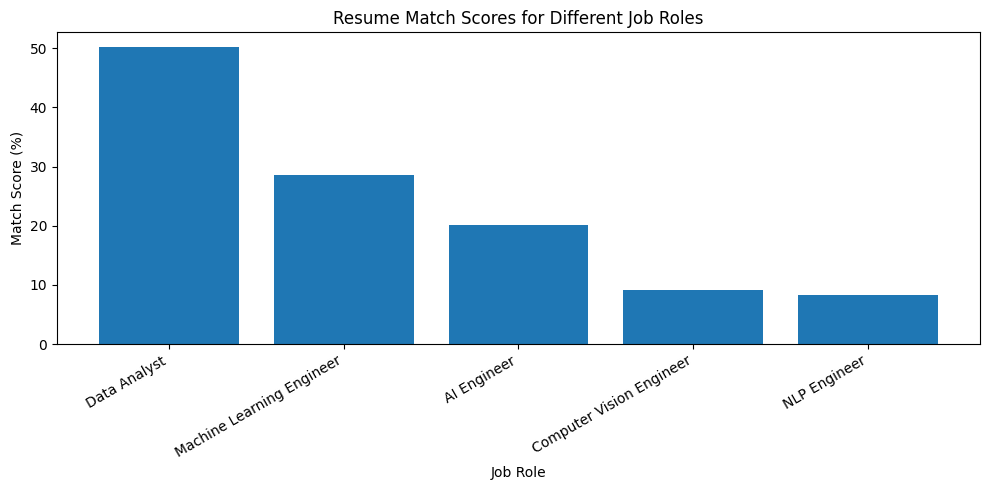

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(results["Job Role"], results["Match Score (%)"])

plt.title("Resume Match Scores for Different Job Roles")
plt.xlabel("Job Role")
plt.ylabel("Match Score (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [16]:
results.to_csv("job_match_results.csv", index=False)

print("Job match results saved successfully!")

Job match results saved successfully!


In [17]:
roadmap_df = pd.DataFrame(
    list(learning_resources.items()),
    columns=["Skill", "Learning Task"]
)

roadmap_df.to_csv("learning_roadmap.csv", index=False)

print("Learning roadmap saved successfully!")

Learning roadmap saved successfully!


In [18]:
app_code = r'''
import streamlit as st
import pandas as pd
import re
from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

st.set_page_config(page_title="AI Resume Analyzer", page_icon="📄")

st.title("AI Resume Analyzer & Job Recommendation System")
st.write("Upload your resume to explore job-role matches and skill gaps.")
st.info("Match scores are text-similarity estimates, not guarantees of job suitability.")

job_roles = {
    "Data Analyst": ["Python", "SQL", "Excel", "Pandas", "Power BI", "Statistics", "Data Visualization"],
    "Machine Learning Engineer": ["Python", "Machine Learning", "Scikit-learn", "Pandas", "NumPy", "TensorFlow", "Docker"],
    "AI Engineer": ["Python", "Artificial Intelligence", "Deep Learning", "LLM", "RAG", "APIs", "TensorFlow"],
    "NLP Engineer": ["Python", "NLP", "Transformers", "Hugging Face", "Machine Learning", "Deep Learning"],
    "Computer Vision Engineer": ["Python", "OpenCV", "CNN", "Deep Learning", "Machine Learning", "YOLO"]
}

def extract_text(uploaded_file):
    name = uploaded_file.name.lower()
    if name.endswith(".pdf"):
        reader = PdfReader(uploaded_file)
        return " ".join(page.extract_text() or "" for page in reader.pages)
    elif name.endswith(".docx"):
        doc = Document(uploaded_file)
        return " ".join(p.text for p in doc.paragraphs)
    return ""

uploaded_file = st.file_uploader("Upload resume (PDF or DOCX)", type=["pdf", "docx"])

if uploaded_file:
    resume_text = extract_text(uploaded_file)
    cleaned_text = re.sub(r"[^a-z0-9+#.\s]", " ", resume_text.lower())
    cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

    if not cleaned_text:
        st.error("No readable text found. Please try another PDF or DOCX file.")
    else:
        skill_dictionary = [
            "python", "sql", "excel", "pandas", "numpy", "power bi",
            "statistics", "data visualization", "machine learning",
            "scikit-learn", "scikit learn", "tensorflow",
            "artificial intelligence", "deep learning", "llm", "rag",
            "apis", "nlp", "transformers", "hugging face", "opencv",
            "cnn", "yolo", "docker", "java", "c++", "git",
            "jupyter notebook", "google colab", "matplotlib",
            "fastapi", "dbms", "classification", "regression",
            "feature engineering", "data cleaning", "model evaluation"
        ]

        found_skills = sorted({
            skill for skill in skill_dictionary
            if re.search(r"(?<![a-z0-9])" + re.escape(skill) + r"(?![a-z0-9])", cleaned_text)
        })

        st.subheader("Skills Detected")
        if found_skills:
            st.write(", ".join(found_skills))
        else:
            st.warning("No listed skills were detected.")

        resume_profile = " ".join(found_skills)
        job_profiles = [" ".join(skills).lower() for skills in job_roles.values()]

        if resume_profile.strip():
            vectorizer = TfidfVectorizer()
            matrix = vectorizer.fit_transform([resume_profile.lower()] + job_profiles)
            scores = cosine_similarity(matrix[0:1], matrix[1:])[0] * 100
        else:
            scores = [0] * len(job_roles)

        results = pd.DataFrame({
            "Job Role": list(job_roles.keys()),
            "Match Score (%)": [round(float(score), 2) for score in scores]
        }).sort_values("Match Score (%)", ascending=False).reset_index(drop=True)

        st.subheader("Job Role Match Scores")
        st.dataframe(results, use_container_width=True)
        st.bar_chart(results.set_index("Job Role")["Match Score (%)"])

        st.subheader("Top 3 Job Recommendations")
        for _, row in results.head(3).iterrows():
            st.write(f"**{row['Job Role']}** — {row['Match Score (%)']}% text similarity")

        selected_role = st.selectbox("Choose a job role for skill-gap analysis", list(job_roles.keys()))
        required_skills = job_roles[selected_role]
        found_lower = set(found_skills)
        skills_present = [s for s in required_skills if s.lower() in found_lower]
        missing_skills = [s for s in required_skills if s.lower() not in found_lower]

        st.subheader("Skills You Have")
        st.write(", ".join(skills_present) if skills_present else "No listed required skills detected.")

        st.subheader("Skills to Learn")
        st.write(", ".join(missing_skills) if missing_skills else "All listed skills were detected.")

        st.subheader("Learning Roadmap")
        for week, skill in enumerate(missing_skills, start=1):
            st.write(f"**Week {week}: {skill}**")
            st.write(f"Suggested task: Practice {skill} and complete a small project using it.")

        st.download_button(
            "Download Job Match Results (CSV)",
            data=results.to_csv(index=False).encode("utf-8"),
            file_name="job_match_results.csv",
            mime="text/csv"
        )
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [19]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("File size:", os.path.getsize("app.py"), "bytes")

app.py exists: True
File size: 5015 bytes


In [20]:
requirements = """streamlit
pandas
pypdf
python-docx
scikit-learn
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [35]:
!pip install -r requirements.txt

In [36]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [37]:
!npm install -g localtunnel
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
changed 22 packages in 4s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼⠙⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://late-drinks-film.loca.lt
^C


In [46]:
!tail -n 60 /content/streamlit.log



2026-10-11 13:19:42.603 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.106.229.48:8501

  Stopping...


In [47]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", e)

Error: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78ea80cbe900>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [48]:
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 < /dev/null &

In [49]:
import time
import requests

time.sleep(5)

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", e)

Status: 200
Response: ok


In [50]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦your url is: https://true-ducks-wish.loca.lt
^C


In [52]:

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb



(Reading database ... 122819 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.0) over (2026.10.0) ...
Setting up cloudflared (2026.10.0) ...


In [53]:

!nohup cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate > /content/cloudflared.log 2>&1 < /dev/null &


In [54]:

import time
import re

for _ in range(15):
    time.sleep(2)
    with open("/content/cloudflared.log") as f:
        log = f.read()

    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log)

    if match:
        print("Your website link:", match.group(0))
        break
else:
    print(log[-2000:])


Your website link: https://logical-static-arranged-cfr.trycloudflare.com


In [55]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print(r.status_code, r.text)
except Exception as e:
    print(e)

HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78ea80ce65d0>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [56]:
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 < /dev/null &

In [57]:
import time
import requests

time.sleep(5)

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Status:", r.status_code, r.text)
except Exception as e:
    print("Error:", e)

Status: 200 ok


In [58]:
!pkill -f cloudflared

In [59]:
!nohup cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate > /content/cloudflared.log 2>&1 < /dev/null &

In [61]:
import time
import re

time.sleep(5)

with open("/content/cloudflared.log") as f:
    log = f.read()

match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log)
print(match.group(0) if match else log[-2000:])

https://priority-remain-allow-investors.trycloudflare.com
